In [101]:
# !pip install numpy
# !pip install scikit-learn
# !pip install torch
# !pip install pandas
# !pip install matplotlib
# !pip install torchvision
# !pip install seaborn

In [102]:
import random
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import distance
import sklearn.metrics
import sklearn.datasets
from sklearn.datasets import fetch_openml, fetch_california_housing, \
load_diabetes, load_breast_cancer, load_wine
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

## Datasets ##

In [103]:
# --- Load Data ---
california = fetch_california_housing(as_frame=True)

# The data is already in a convenient pandas DataFrame format
X = california.data
y = california.target

# --- Explore Data ---
print("\n--- California Housing Dataset ---")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst 5 rows of features (X):")
print(X.head())

# --- Transform Data ---
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nShape of scaled training features:", X_train_scaled.shape)



--- California Housing Dataset ---
Features shape: (20640, 8)
Target shape: (20640,)

First 5 rows of features (X):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Shape of scaled training features: (16512, 8)


## SVR ##


--- SVR Model Evaluation ---
Mean Squared Error (MSE): 1.23
R-squared (R2 Score): 0.12


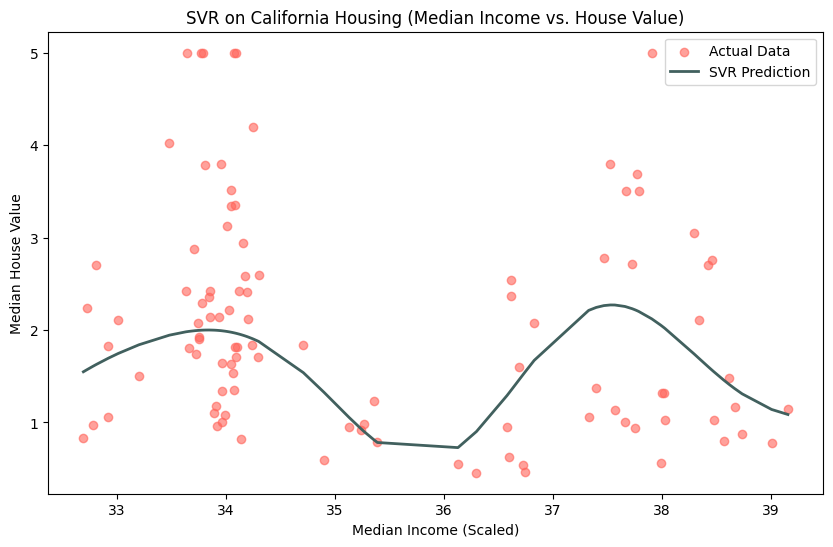

In [104]:
# 1. Load and Prepare Data
# --------------------------------------------------
california = fetch_california_housing()
# For simplicity, let's use only one feature (Median Income) to make it easy to visualize
X = california.data[:, np.newaxis, 6]  # Median Income feature
y = california.target

# Use a smaller subset of data for faster training and clearer visualization
X, _, y, _ = train_test_split(X, y, train_size=500, random_state=42)

# Split the subset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Scale the Features (CRITICAL STEP FOR SVR)
# --------------------------------------------------
# SVR is not scale-invariant, so scaling is essential.
# We scale both features (X) and the target (y) for better performance.
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Reshape y to be a 2D array for the scaler, then flatten it back
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

# 3. Train the SVR Model
# --------------------------------------------------
# We'll use the 'rbf' kernel for non-linear relationships
# The hyperparameters C and gamma are often tuned using GridSearchCV
svr = svm.SVR(kernel='rbf', C=10, gamma='auto', epsilon=0.1)

svr.fit(X_train_scaled, y_train_scaled)

# 4. Make Predictions and Evaluate
# --------------------------------------------------
# Predict on the scaled test data
y_pred_scaled = svr.predict(X_test_scaled)

# Inverse transform the predictions to get them back to the original scale
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- SVR Model Evaluation ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2 Score): {r2:.2f}")

# 5. Visualize the Results
# --------------------------------------------------
plt.figure(figsize=(10, 6))
# Sort values for a clean line plot
sort_axis = np.argsort(X_test.ravel())
X_test_sorted = X_test.ravel()[sort_axis]
y_pred_sorted = y_pred[sort_axis]

plt.scatter(X_test, y_test, color='#FF6359', label='Actual Data', alpha=0.6)
plt.plot(X_test_sorted, y_pred_sorted, color='#41605E', lw=2, label='SVR Prediction')
plt.title('SVR on California Housing (Median Income vs. House Value)')
plt.xlabel('Median Income (Scaled)')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

## My Support Vector Machine ##

### Epsilon Insensitive Loss function and it's Derivative

In [105]:
def EpsilonInsensitiveLoss(y_true, y_pred, epsilon):
    error = np.abs(y_true - y_pred)
    return np.maximum(0, error - epsilon)

def EpsilonInsensitiveLossPrime(y_true, y_pred, epsilon):
    error = y_true - y_pred
    if np.abs(error) <= epsilon:
        return 0
    elif error > epsilon:
        return -1
    else:
        return 1

### Dense Layer ###

In [106]:
class Dense:
    def __init__(self, input_size, output_size):
        self.weights = np.random.randn(input_size, output_size) * 0.01
        self.bias = np.zeros((1, output_size))
        self.input = None
        self.grad = {'weights': None, 'bias': None}

    def forward(self, input_data):
        self.input = input_data
        if self.input.ndim == 1:
            self.input = self.input.reshape(1, -1)
        return np.dot(self.input, self.weights) + self.bias

    def backward(self, output_gradient):
        if not isinstance(output_gradient, np.ndarray):
            output_gradient = np.array([[output_gradient]])
        elif output_gradient.ndim == 0:
            output_gradient = output_gradient.reshape(1, 1)
        
        self.grad['weights'] = np.dot(self.input.T, output_gradient)
        self.grad['bias'] = np.sum(output_gradient, axis=0, keepdims=True)
        input_gradient = np.dot(output_gradient, self.weights.T)
        return input_gradient

### Stochastic Gradient Descent Optimizer with Weight Decay ###

In [107]:
class SGD():
    def __init__(self, layers, learning_rate = 0.001, weight_decay=0.01):
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.layers = layers

    def update(self, gradients):
        for i, layer in enumerate(reversed(self.layers)):
            if isinstance(layer, Dense):
                layer.weights *= (1 - self.learning_rate * self.weight_decay) # L2 Regularization
                layer.weights -= self.learning_rate * gradients[i]['weights']
                layer.bias -= self.learning_rate * gradients[i]['bias']

           

### Support Vector Machine ###

In [108]:
class MySVR():
    
    def __init__(self, layers=None, max_iter=200, learning_rate=0.001, epsilon=0.1, weight_decay=0.01):
        self.layers = layers
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.epsilon = epsilon
        self.weight_decay = weight_decay

    def save_model(self, name, epoch):
        weights = []
        bias = []
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                weights.append(layer.weights)
                bias.append(layer.bias)
            else:
                weights.append([])
                bias.append([])
        
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'ab')
        pickle.dump(weights, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'ab')
        pickle.dump(bias, dbfile)                    
        dbfile.close()

    def load_model(self, name, epoch):
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'rb')    
        weights = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'rb')    
        bias = pickle.load(dbfile)
        dbfile.close()

        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights = weights[i]
                layer.bias = bias[i]

    def train(self, X_train, y_train, X_test=None, y_test=None):
        # Hyperparameters are taken from `self`
        optim = SGD(self.layers, self.learning_rate, self.weight_decay)
        
        # Flag to enable verbose logging only if validation data is provided
        verbose = X_test is not None and y_test is not None

        for e in range(self.max_iter):
            # ... (the rest of your training loop for one epoch) ...
            permutation = np.random.permutation(X_train.shape[0])
            X_shuffled = X_train[permutation]
            y_shuffled = y_train[permutation]
            
            for i in range(X_train.shape[0]):
                x, y_true = X_shuffled[i], y_shuffled[i]
                y_pred = self._forward(x)[0][0]
                loss_gradient = EpsilonInsensitiveLossPrime(y_true, y_pred, self.epsilon)
                
                # ... (backpropagation logic) ...
                grad, next_grad = [], loss_gradient
                for j, layer in enumerate(reversed(self.layers)):
                    grad.append(None); next_grad = layer.backward(next_grad); grad[j] = layer.grad
                optim.update(grad)

            # --- Optional verbose logging using the validation set ---
            if verbose and (e + 1) % 20 == 0: # Print every 20 epochs
                val_preds = self.predict(X_test)
                val_mse = np.mean((y_test - val_preds)**2) # Simple MSE calculation
                print(f"  Epoch {e + 1}/{self.max_iter}, Validation MSE: {val_mse:.4f}")

    def _forward(self, X):
        output = X
        for layer in self.layers:
            output = layer.forward(output)
        return np.array(output)

    def predict(self, X):
        if X.ndim == 1: return self._forward(X)
        predictions = np.array([self._forward(x) for x in X])
        return predictions.squeeze()

## Train and evaluate ##

In [109]:
# Corrected MySVRAdapter that handles validation data

from sklearn.base import BaseEstimator, RegressorMixin

class MySVRAdapter(BaseEstimator, RegressorMixin):
    def __init__(self, layers=None, max_iter=200, learning_rate=0.001, epsilon=0.1, weight_decay=0.01, 
                 # --- Add validation data to __init__ ---
                 validation_data=None):
        
        # Store all parameters as attributes
        self.layers = layers
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.epsilon = epsilon
        self.weight_decay = weight_decay
        self.validation_data = validation_data

    def fit(self, X, y):
        # Create a fresh instance of the model
        self._model = MySVR(
            layers=self.layers,
            max_iter=self.max_iter,
            learning_rate=self.learning_rate,
            epsilon=self.epsilon,
            weight_decay=self.weight_decay
        )
        
        # --- Unpack validation data and pass it to train ---
        val_X, val_y = (None, None)
        if self.validation_data is not None:
            val_X, val_y = self.validation_data

        # Call the train method with the validation data
        self._model.train(X, y, X_test=val_X, y_test=val_y)
        
        return self

    def predict(self, X):
        if not hasattr(self, '_model'):
            raise RuntimeError("You must call fit before calling predict.")
        return self._model.predict(X)


In [110]:
# Cell: SVR Comparison Suite

import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import the models to compare
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# Import metrics
from sklearn.metrics import mean_squared_error, r2_score

# 1. --- DATA PREPARATION ---
print("Loading and preparing data...")
housing = fetch_california_housing()
X, y = housing.data, housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling is crucial for SVR, Ridge, and k-NN, but not for Random Forest.
# However, we scale for all to ensure a fair comparison on the same data representation.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Data ready.\n")


# 2. --- DEFINE AND TRAIN MODELS ---
# We'll store our models in a dictionary for easy iteration
n_features = X.shape[1]
# Define your model's architecture
my_svr_layers = [Dense(n_features, 1)]

models = {
    "MySVR (Linear)": MySVRAdapter(
        layers=my_svr_layers, 
        max_iter=200, 
        learning_rate=0.001,
        validation_data=(X_test_scaled, y_test) # Pass test set here
    ),
    "SVR (Linear Kernel)": SVR(kernel='linear', C=1.0),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=10),
    "Ridge Regression": Ridge(alpha=1.0),
    "k-NN Regressor": KNeighborsRegressor(n_neighbors=7),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}
# Dictionary to store the results
results = {}

print("Training and evaluating models...")
for name, model in models.items():
    print(f"  Training {name}...")
    # Train the model
    model.fit(X_train_scaled, y_train)
    
    # Make predictions
    predictions = model.predict(X_test_scaled)
    
    # Calculate metrics and store them
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results[name] = {"MSE": mse, "RMSE": np.sqrt(mse), "R-squared": r2}

print("\nAll models trained and evaluated.\n")


# 3. --- DISPLAY RESULTS ---
# Convert the results dictionary to a pandas DataFrame for nice formatting
results_df = pd.DataFrame(results).T # Transpose to have model names as rows
results_df = results_df.sort_values(by='RMSE', ascending=True) # Sort by best performance

print("--- Model Performance Comparison ---")
print(results_df)


Loading and preparing data...
Data ready.

Training and evaluating models...
  Training MySVR (Linear)...
  Epoch 20/200, Validation MSE: 0.5680
  Epoch 40/200, Validation MSE: 0.5714
  Epoch 60/200, Validation MSE: 0.5910
  Epoch 80/200, Validation MSE: 0.5930
  Epoch 100/200, Validation MSE: 0.5735
  Epoch 120/200, Validation MSE: 0.5745
  Epoch 140/200, Validation MSE: 0.5746
  Epoch 160/200, Validation MSE: 0.6017
  Epoch 180/200, Validation MSE: 0.5742
  Epoch 200/200, Validation MSE: 0.6028
  Training SVR (Linear Kernel)...
  Training SVR (RBF Kernel)...
  Training Ridge Regression...
  Training k-NN Regressor...
  Training Random Forest...

All models trained and evaluated.

--- Model Performance Comparison ---
                          MSE      RMSE  R-squared
Random Forest        0.255170  0.505143   0.805275
SVR (RBF Kernel)     0.323695  0.568942   0.752982
k-NN Regressor       0.428334  0.654472   0.673130
Ridge Regression     0.555855  0.745557   0.575816
SVR (Linear Kerne


--- Generating Comprehensive Evaluation Report ---

1. Advanced Metrics on the Test Set:
                         RMSE       MAE  R-squared  Max Error  \
Model                                                           
Random Forest        0.505143  0.327425   0.805275   3.045841   
SVR (RBF Kernel)     0.568942  0.377444   0.752982   3.576105   
k-NN Regressor       0.654472  0.444039   0.673130   4.160010   
Ridge Regression     0.745557  0.533193   0.575816   9.867735   
SVR (Linear Kernel)  0.761101  0.511994   0.557943  11.572551   
MySVR (Linear)       0.776394  0.518170   0.540001  13.889451   

                     Predict Time (ms)  
Model                                   
Random Forest                67.473888  
SVR (RBF Kernel)           3706.307411  
k-NN Regressor              268.751621  
Ridge Regression              0.169992  
SVR (Linear Kernel)         954.771519  
MySVR (Linear)               15.262365  

2. Cross-Validation (R-squared) Performance:
  Running CV fo

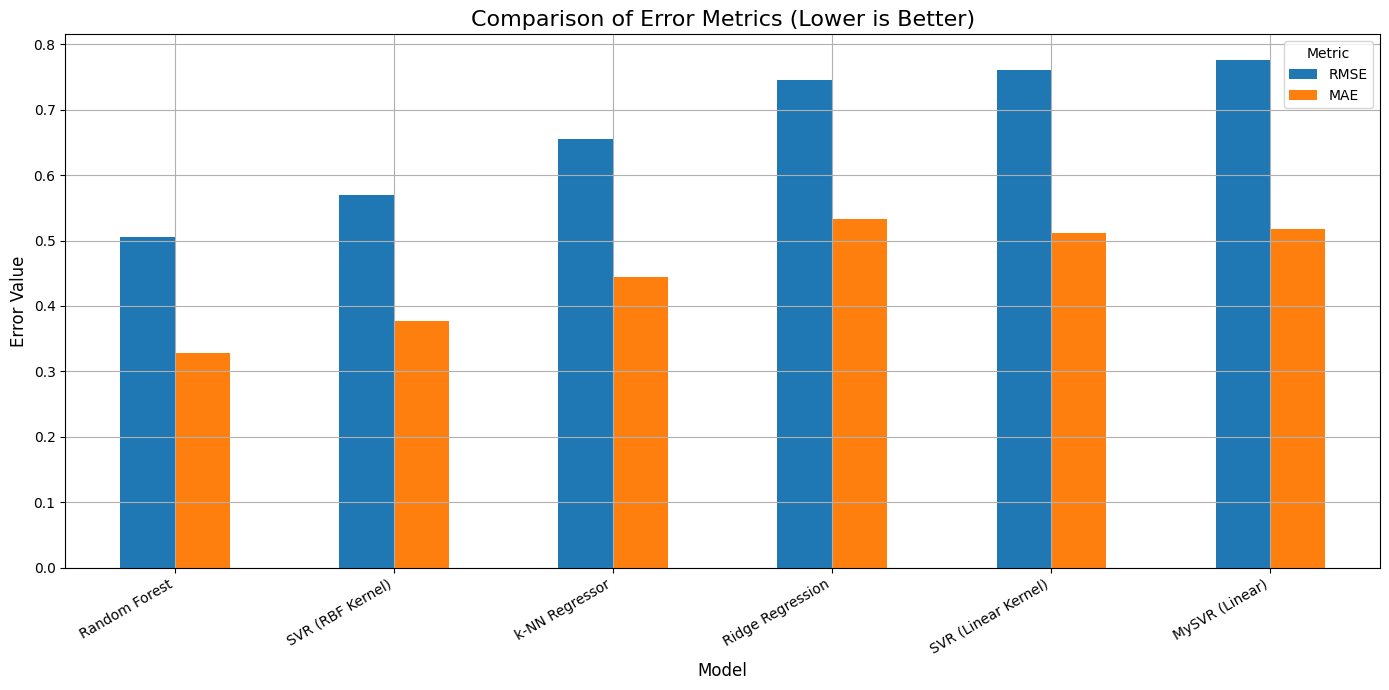

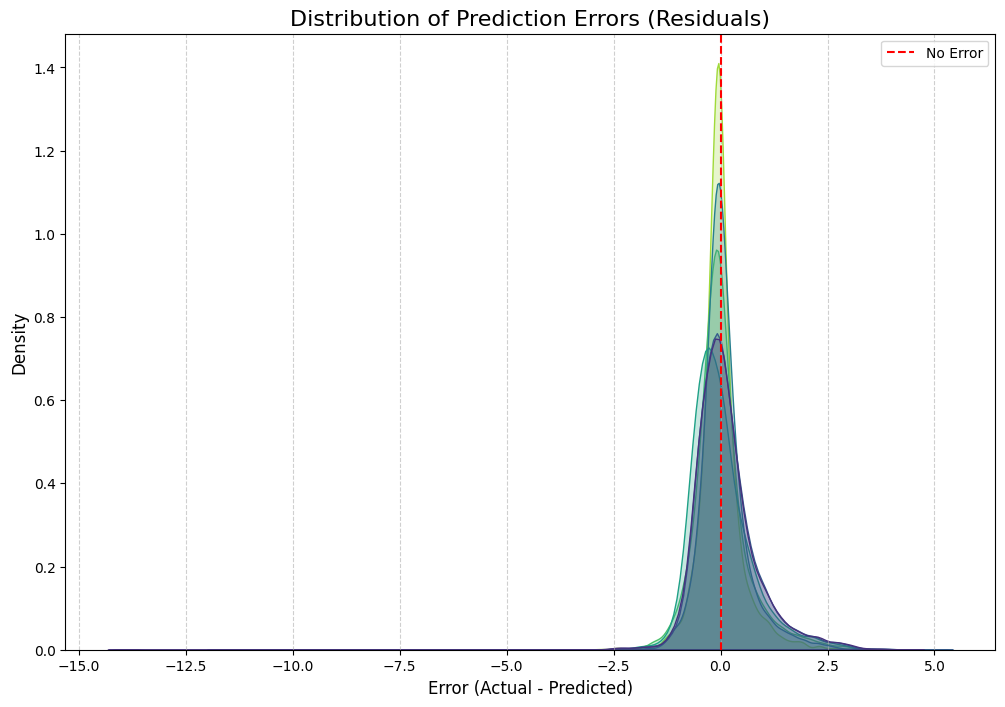

In [111]:
import time

from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, max_error

# 5. --- COMPREHENSIVE METRICS & EVALUATION ---

print("\n--- Generating Comprehensive Evaluation Report ---")

# A. --- Advanced Test Set Metrics & Prediction Latency ---
print("\n1. Advanced Metrics on the Test Set:")
advanced_results = []
for name, model in models.items():
    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X_test_scaled)
    end_time = time.time()
    predict_time = (end_time - start_time) * 1000 # Convert to milliseconds

    advanced_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R-squared": r2_score(y_test, predictions),
        "Max Error": max_error(y_test, predictions),
        "Predict Time (ms)": predict_time
    })

results_df = pd.DataFrame(advanced_results).set_index('Model').sort_values(by='RMSE')
print(results_df)


# B. --- Robustness Check with Cross-Validation ---
print("\n2. Cross-Validation (R-squared) Performance:")
# Note: CV can be slow, especially for MySVR and RandomForest. We use 3 folds.
cv_results = {}
for name, model in models.items():
    print(f"  Running CV for {name}...")
    # Use the entire scaled dataset for a more robust CV score
    # We use a pipeline for models that need scaling, but for simplicity here, we'll use the scaled data
    # Important: Re-fitting happens inside cross_val_score
    scores = cross_val_score(model, X_train_scaled, y_train, cv=3, scoring='r2', n_jobs=-1)
    cv_results[name] = scores

cv_df = pd.DataFrame(cv_results).T # Transpose to get models as rows
cv_df['Mean R2'] = cv_df.mean(axis=1)
cv_df['Std Dev R2'] = cv_df.std(axis=1)
print(cv_df[['Mean R2', 'Std Dev R2']].sort_values(by='Mean R2', ascending=False))


# C. --- Advanced Visualizations ---
print("\n3. Generating Advanced Visualizations...")

# Plot 1: Bar Chart of Multiple Metrics (RMSE and MAE)
results_df[['RMSE', 'MAE']].plot(kind='bar', figsize=(14, 7), grid=True)
plt.title('Comparison of Error Metrics (Lower is Better)', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Error Value', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

# Plot 2: Error Distribution Plot (Kernel Density Estimate)
plt.figure(figsize=(12, 8))
error_data = []
for name, model in models.items():
    predictions = model.predict(X_test_scaled)
    residuals = y_test - predictions
    for r in residuals:
        error_data.append({'Model': name, 'Error': r})

error_df = pd.DataFrame(error_data)

sns.kdeplot(data=error_df, x='Error', hue='Model', fill=True, common_norm=False, palette='viridis')
plt.axvline(0, color='red', linestyle='--', label='No Error')
plt.title('Distribution of Prediction Errors (Residuals)', fontsize=16)
plt.xlabel('Error (Actual - Predicted)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()
